===== PHÂN TÍCH DỮ LIỆU DIABETES =====

5 dòng dữ liệu đầu tiên:
        bmi        bp        s5  Target
0  0.061696  0.021872  0.019907   151.0
1 -0.051474 -0.026328 -0.068332    75.0
2  0.044451 -0.005670  0.002861   141.0
3 -0.011595 -0.036656  0.022688   206.0
4 -0.036385  0.021872 -0.031988   135.0

Kích thước dữ liệu: (442, 4)

Thông tin dữ liệu:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 442 entries, 0 to 441
Data columns (total 4 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   bmi     442 non-null    float64
 1   bp      442 non-null    float64
 2   s5      442 non-null    float64
 3   Target  442 non-null    float64
dtypes: float64(4)
memory usage: 13.9 KB
None

Thống kê mô tả:
                bmi            bp            s5      Target
count  4.420000e+02  4.420000e+02  4.420000e+02  442.000000
mean  -2.245564e-16 -4.797570e-17  9.293722e-17  152.133484
std    4.761905e-02  4.761905e-02  4.761905e-02   77.093005
min   -9.027530e

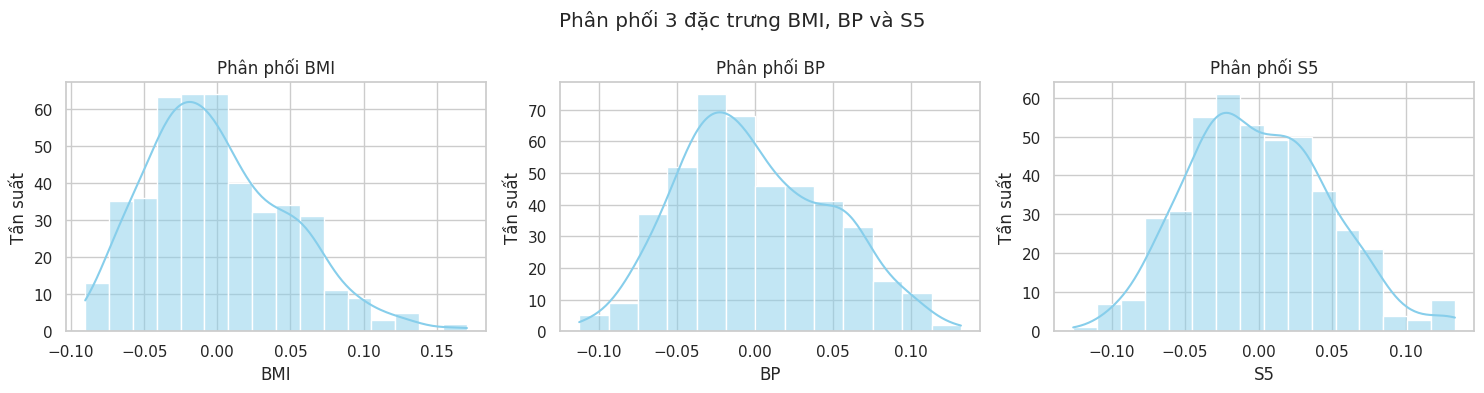

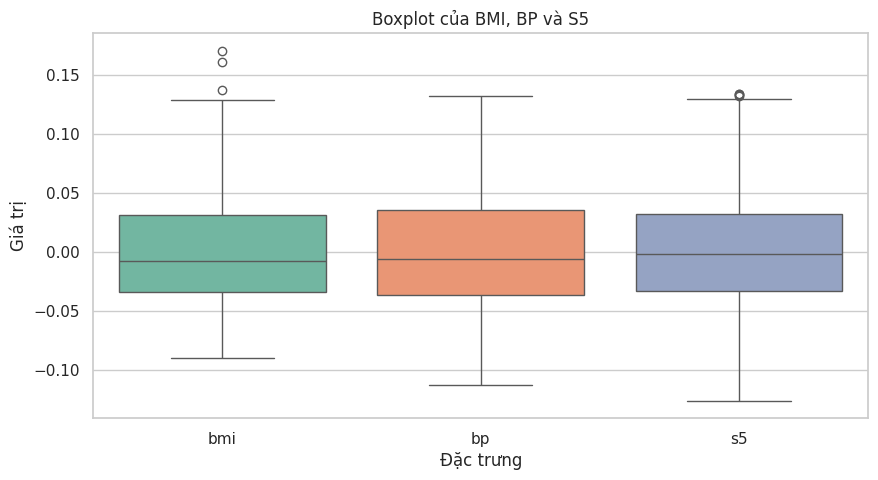

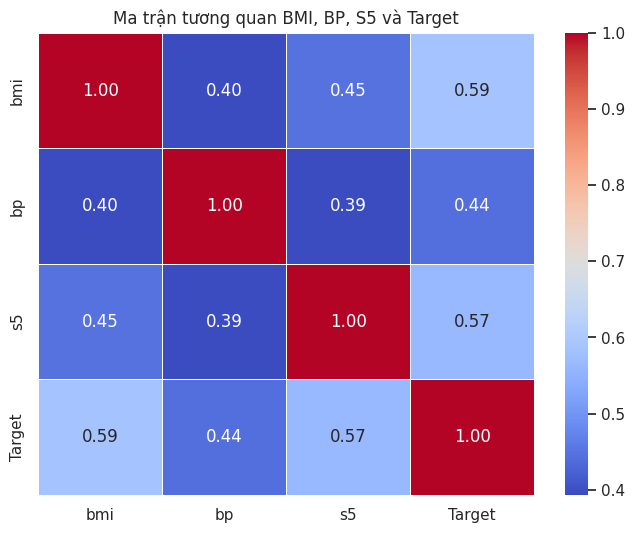

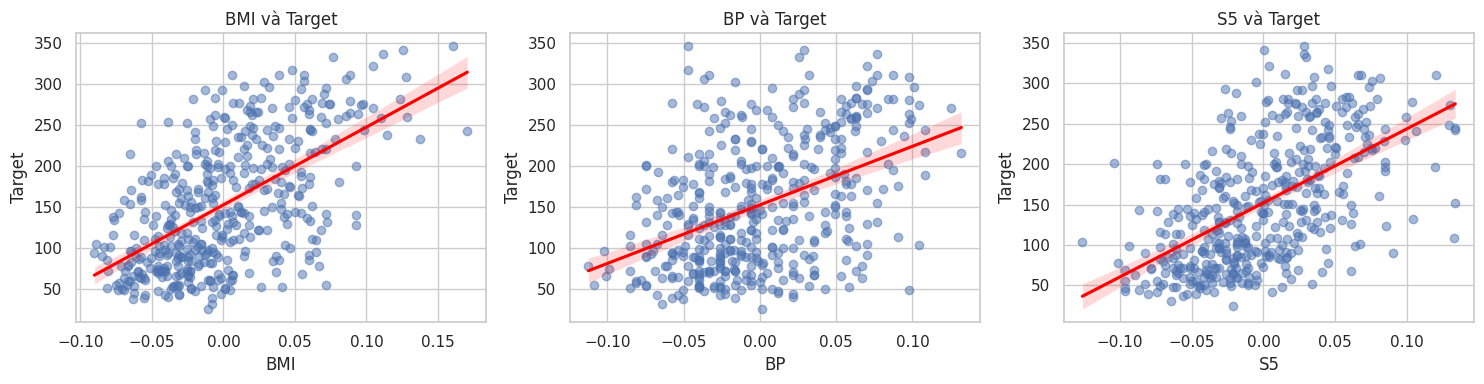

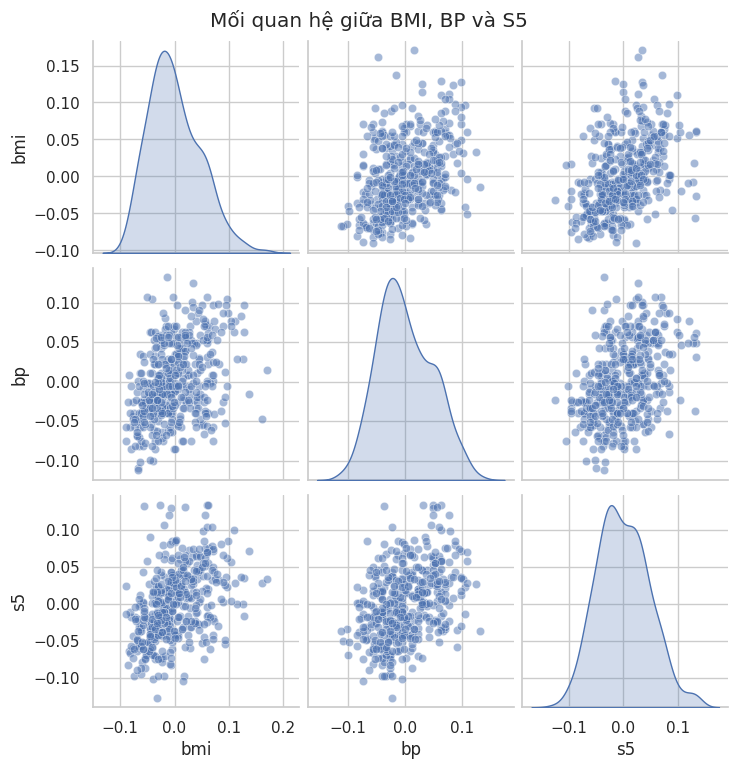


===== KẾT QUẢ PHÂN TÍCH EDA =====

Đặc trưng BMI:
Giá trị trung bình: -0.0
Độ lệch chuẩn: 0.0476
Giá trị nhỏ nhất: -0.0903
Giá trị lớn nhất: 0.1706

Đặc trưng BP:
Giá trị trung bình: -0.0
Độ lệch chuẩn: 0.0476
Giá trị nhỏ nhất: -0.1124
Giá trị lớn nhất: 0.132

Đặc trưng S5:
Giá trị trung bình: 0.0
Độ lệch chuẩn: 0.0476
Giá trị nhỏ nhất: -0.1261
Giá trị lớn nhất: 0.1336

Tương quan với Target:
bmi       0.586450
bp        0.441482
s5        0.565883
Target    1.000000
Name: Target, dtype: float64

===== KẾT LUẬN =====
1. BMI có mối tương quan dương với Target.
2. BP có mối tương quan dương với Target.
3. S5 có mối tương quan dương với Target.
4. Các đặc trưng có mức độ ảnh hưởng khác nhau.
5. Kết quả EDA hỗ trợ lựa chọn đặc trưng cho mô hình học máy.


In [1]:

# ==========================================================
# PHÂN TÍCH KHÁM PHÁ DỮ LIỆU DIABETES (EDA)
# KHẢO SÁT 3 ĐẶC TRƯNG BMI, BP VÀ S5
# ==========================================================

# 1. IMPORT THƯ VIỆN
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_diabetes

sns.set_theme(style="whitegrid")

# 2. TẢI VÀ ĐỌC DỮ LIỆU
diabetes = load_diabetes()

df = pd.DataFrame(
    diabetes.data,
    columns=diabetes.feature_names
)

df['Target'] = diabetes.target

# Chọn 3 đặc trưng BMI, BP và S5
features = ['bmi', 'bp', 's5']
data = df[features + ['Target']]

print("===== PHÂN TÍCH DỮ LIỆU DIABETES =====")
print("\n5 dòng dữ liệu đầu tiên:")
print(data.head())

# 3. KHÁM PHÁ TỔNG QUAN DỮ LIỆU
print("\nKích thước dữ liệu:", data.shape)

print("\nThông tin dữ liệu:")
print(data.info())

print("\nThống kê mô tả:")
print(data.describe())

print("\nKiểm tra dữ liệu thiếu:")
print(data.isnull().sum())

# 4. PHÂN TÍCH PHÂN PHỐI DỮ LIỆU
plt.figure(figsize=(15, 4))

for i, feature in enumerate(features):
    plt.subplot(1, 3, i + 1)
    sns.histplot(data[feature], kde=True, color='skyblue')
    plt.title(f'Phân phối {feature.upper()}')
    plt.xlabel(feature.upper())
    plt.ylabel('Tần suất')

plt.suptitle('Phân phối 3 đặc trưng BMI, BP và S5')
plt.tight_layout()
plt.show()

# 5. PHÂN TÍCH GIÁ TRỊ NGOẠI LỆ (BOXPLOT)
plt.figure(figsize=(10, 5))

sns.boxplot(data=data[features], palette='Set2')

plt.title('Boxplot của BMI, BP và S5')
plt.xlabel('Đặc trưng')
plt.ylabel('Giá trị')
plt.show()

# 6. PHÂN TÍCH MA TRẬN TƯƠNG QUAN
corr = data[features + ['Target']].corr()

plt.figure(figsize=(8, 6))

sns.heatmap(
    corr,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    linewidths=0.5
)

plt.title('Ma trận tương quan BMI, BP, S5 và Target')
plt.show()

# 7. PHÂN TÍCH MỐI QUAN HỆ VỚI TARGET
plt.figure(figsize=(15, 4))

for i, feature in enumerate(features):
    plt.subplot(1, 3, i + 1)

    sns.regplot(
        data=data,
        x=feature,
        y='Target',
        scatter_kws={'alpha': 0.5},
        line_kws={'color': 'red'}
    )

    plt.title(f'{feature.upper()} và Target')
    plt.xlabel(feature.upper())
    plt.ylabel('Target')

plt.tight_layout()
plt.show()

# 8. PHÂN TÍCH MỐI QUAN HỆ GIỮA 3 ĐẶC TRƯNG
sns.pairplot(
    data[features],
    diag_kind='kde',
    plot_kws={'alpha': 0.5}
)

plt.suptitle('Mối quan hệ giữa BMI, BP và S5', y=1.02)
plt.show()

# 9. THỐNG KÊ VÀ TỔNG KẾT KẾT QUẢ
print("\n===== KẾT QUẢ PHÂN TÍCH EDA =====")

for feature in features:
    print(f"\nĐặc trưng {feature.upper()}:")
    print("Giá trị trung bình:", round(data[feature].mean(), 4))
    print("Độ lệch chuẩn:", round(data[feature].std(), 4))
    print("Giá trị nhỏ nhất:", round(data[feature].min(), 4))
    print("Giá trị lớn nhất:", round(data[feature].max(), 4))

print("\nTương quan với Target:")
print(data[features + ['Target']].corr()['Target'])

# 10. KẾT LUẬN
print("\n===== KẾT LUẬN =====")
print("1. BMI có mối tương quan dương với Target.")
print("2. BP có mối tương quan dương với Target.")
print("3. S5 có mối tương quan dương với Target.")
print("4. Các đặc trưng có mức độ ảnh hưởng khác nhau.")
print("5. Kết quả EDA hỗ trợ lựa chọn đặc trưng cho mô hình học máy.")
